# 2. Définir la qualité d'une soudure

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Le problème central du projet

L'énoncé demande de prédire la **qualité** d'une soudure. Or le jeu de données
ne contient **aucune variable de qualité**. Il contient des propriétés
mécaniques mesurées : une résistance en mégapascals, un allongement en
pourcents, une énergie de rupture en joules.

La variable à prédire n'existe donc pas. **Il faut la construire**, et c'est
l'objet de ce notebook.

Ce n'est pas un détail technique préalable, c'est la décision la plus lourde du
projet. Tout ce qui suit, le choix des modèles, leurs performances, les
recommandations finales, dépend de cette définition. Un modèle excellent sur une
mauvaise définition de la qualité est un mauvais modèle.

## Un avertissement sur la chronologie

**Nous n'avons pas procédé dans cet ordre, et il serait malhonnête de le laisser
croire.**

Notre premier réflexe a été de retenir une définition raisonnable, combinant la
résistance à la traction et l'allongement, et de construire des modèles autour
d'elle. C'est seulement après avoir comparé plusieurs familles de modèles que
nous nous sommes demandé si cette définition était la bonne, et nous sommes
revenus en arrière pour la comparer à d'autres.

Ce notebook présente cette comparaison dans l'ordre logique, c'est-à-dire avant
les modèles. Mais le détail de l'aller-retour, y compris les résultats obtenus
sur la première définition, figure dans les notebooks d'exploration
`notebooks/02_construction_cible.ipynb`, `notebooks/11_comparaison_cibles.ipynb`
et `notebooks/12_reentrainement_cible_y3.ipynb`.

**Nous avons eu raison de revenir en arrière**, et la section 5 montre pourquoi :
le critère qui paraît le plus naturel pour choisir une cible, la qualité avec
laquelle un modèle la prédit, aurait conduit au pire des choix possibles.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu2"
OUT.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

colonnes_texte = ["AC_DC", "Electrode_pol", "WeldType", "WeldID",
                  "hardness_scale"]
propre = pd.read_csv(PROCESSED / "welddb_clean.csv", index_col="row_id",
                     dtype={c: str for c in colonnes_texte},
                     keep_default_na=False, na_values=[""],
                     float_precision="round_trip")
groupes = pd.read_csv(PROCESSED / "welddb_groups.csv",
                      index_col="row_id")["groupe"]

# La séparation développement et test est faite une fois pour toutes, par
# groupes, et elle est identique dans tous les notebooks du projet.
indices_dev, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
                                        random_state=GRAINE)
                      .split(propre, groups=groupes))
partition = pd.Series("test", index=propre.index, name="partition")
partition.iloc[indices_dev] = "developpement"
dev = partition == "developpement"

print(f"{len(propre)} lignes, {groupes.nunique()} soudures.")
print(f"Développement : {int(dev.sum())} lignes, "
      f"{groupes[dev].nunique()} soudures.")
print(f"Test réservé  : {int((~dev).sum())} lignes, "
      f"{groupes[~dev].nunique()} soudures.")

1652 lignes, 624 soudures.
Développement : 1298 lignes, 499 soudures.
Test réservé  : 354 lignes, 125 soudures.


## 1. Que mesure-t-on quand on parle de qualité ?

Avant de combiner des propriétés, il faut savoir ce que chacune décrit. Le jeu
de données en contient cinq exploitables, et elles ne disent pas la même chose.

### 1.1 Les deux familles de propriétés, et leur opposition

**La résistance**, décrite par deux mesures.

La **limite d'élasticité** est la contrainte au-delà de laquelle le métal se
déforme de façon permanente. En deçà, il revient à sa forme initiale ; au-delà,
il reste déformé. C'est la grandeur que l'on dimensionne dans une structure, car
on ne veut normalement pas la dépasser en service.

La **résistance à la traction** est la contrainte maximale que le métal supporte
avant de rompre. Elle est toujours supérieure à la limite d'élasticité, et leur
rapport mesure la capacité du métal à se renforcer en se déformant.

**La ductilité**, également décrite par deux mesures.

L'**allongement à la rupture** est de combien l'éprouvette s'est étirée avant de
casser, en pourcentage de sa longueur initiale. Un allongement élevé signifie
que le métal se déforme beaucoup avant de rompre.

La **striction** est la réduction de section au point de rupture. Elle mesure la
même aptitude à se déformer, mais localement plutôt que globalement.

**Et une cinquième propriété, à part : la ténacité.**

La **résilience Charpy** est l'énergie absorbée par une éprouvette entaillée
lors d'un choc. Elle mesure la résistance à la rupture **fragile**, c'est-à-dire
brutale et sans déformation préalable. C'est un phénomène différent des quatre
autres, et nous verrons qu'il faut la traiter séparément.

### 1.2 Pourquoi une seule propriété ne peut pas définir la qualité

C'est le point qui rend ce notebook nécessaire, et il est physique avant d'être
statistique.

**Résistance et ductilité s'opposent.** Durcir un acier le rend plus résistant
et moins déformable. Un acier très dur casse net ; un acier très mou plie sans
casser mais ne supporte rien. Une bonne soudure n'est donc pas celle qui
maximise une propriété, c'est celle qui réalise un **compromis acceptable** entre
les deux.

La cellule suivante mesure cette opposition sur nos données.

In [2]:
RESISTANCE = ["YieldStrength_MPa", "UTS_MPa"]
DUCTILITE = ["Elongation_pct", "ReductionArea_pct"]
TENACITE = ["CharpyToughness_J"]
CONDITION = ["CharpyT_C"]
MESURES = RESISTANCE + DUCTILITE + TENACITE

LIBELLES_MESURES = {
    "YieldStrength_MPa": "limite d'élasticité",
    "UTS_MPa": "résistance à la traction",
    "Elongation_pct": "allongement",
    "ReductionArea_pct": "striction",
    "CharpyToughness_J": "résilience Charpy",
}

disponibilite = pd.DataFrame({
    "propriété": [LIBELLES_MESURES[m] for m in MESURES],
    "lignes renseignées": [int(propre[m].notna().sum()) for m in MESURES],
    "soudures": [groupes[propre[m].notna()].nunique() for m in MESURES],
    "médiane": [propre[m].median() for m in MESURES],
}).set_index("propriété")
display(disponibilite.round(1))

# L'opposition entre résistance et ductilité, mesurée.
correlations = propre[RESISTANCE + DUCTILITE].corr()
correlations.index = [LIBELLES_MESURES[m] for m in correlations.index]
correlations.columns = [LIBELLES_MESURES[m] for m in correlations.columns]
print("Corrélations entre les quatre propriétés de traction :")
display(correlations.round(2))

Corrélations entre les quatre propriétés de traction :


,lignes renseignées,soudures,médiane
propriété,,,
limite d'élasticité,780,566,495.0
résistance à la traction,738,533,575.5
allongement,700,501,26.8
striction,705,508,75.0
résilience Charpy,879,341,100.0


,limite d'élasticité,résistance à la traction,allongement,striction
limite d'élasticité,1.00,0.92,-0.68,-0.46
résistance à la traction,0.92,1.00,-0.74,-0.66
allongement,-0.68,-0.74,1.00,0.53
striction,-0.46,-0.66,0.53,1.00


### Ce que montrent les corrélations

Les deux mesures de résistance sont fortement corrélées **entre elles**, et les
deux mesures de ductilité le sont aussi. Cela confirme que chaque famille mesure
bien une seule chose, par deux moyens différents.

**Mais les corrélations entre familles sont négatives, et fortement.** Plus une
soudure est résistante, moins elle est ductile. C'est l'opposition annoncée, et
elle est ici de grande ampleur.

**Conséquence directe : toute définition de la qualité fondée sur une seule
famille récompensera les soudures médiocres dans l'autre.** C'est une certitude
arithmétique, pas une hypothèse, et la section 4 la mesurera.

C'est pourquoi nous ne pouvons pas simplement choisir « la résistance » comme
cible, bien que ce soit la propriété la plus souvent citée.

## 2. Pourquoi on ne peut pas choisir la cible par la performance d'un modèle

Avant de construire des candidates, il faut écarter une méthode qui paraît
naturelle et qui est pourtant invalide.

Le réflexe serait de dire : essayons plusieurs définitions, entraînons un modèle
sur chacune, et gardons celle que le modèle prédit le mieux. C'est tentant, parce
que c'est mesurable et objectif.

**C'est un raisonnement circulaire.** La performance d'un modèle mesure à quel
point une grandeur est **prévisible** à partir de la composition et du procédé.
Elle ne mesure pas à quel point cette grandeur **est** la qualité. Ce sont deux
questions indépendantes.

Pire, les deux sont systématiquement en tension. Une cible qui combine plusieurs
mesures agrège plusieurs essais, donc plusieurs sources d'incertitude
expérimentale, donc elle sera généralement plus difficile à prédire qu'une
mesure unique. **Choisir la cible la mieux prédite revient donc à choisir la
définition la plus simpliste.**

**Notre démarche.** Nous construisons d'abord les candidates, puis nous les
comparons selon **quatre critères qui ne font appel à aucun modèle** et reposent
uniquement sur la structure des données et sur la physique des propriétés. Le
choix est arrêté sur ces critères seuls.

Ce n'est qu'ensuite, en section 5, que nous entraînons des modèles. Non pas pour
choisir, mais pour **vérifier** que le choix ne coûte rien en performance. Et
nous verrons que si nous avions choisi par la performance, nous aurions retenu
la pire définition possible.

## 3. Construire des définitions candidates

### 3.1 Le problème des unités

On ne peut pas additionner 550 mégapascals et 28 pourcents. Il faut d'abord
rendre les propriétés comparables, et une simple division par le maximum ne
suffit pas, car une valeur extrême déformerait toute l'échelle.

**Nous convertissons chaque propriété en rang**, c'est-à-dire en position
relative dans le corpus, entre 0 et 1. Une soudure dont la résistance a le rang
0,8 est plus résistante que 80 % des soudures. Les rangs sont sans unité, donc
combinables, et insensibles aux valeurs extrêmes.

Deux précautions, qui découlent du notebook 1.

**La pondération par soudure.** Les rangs sont calculés en donnant à chaque
soudure un poids total de un, et non à chaque ligne. Sans cela, une soudure
testée vingt fois déformerait l'échelle à elle seule.

**Le traitement des valeurs égales.** Plusieurs soudures peuvent partager la même
valeur mesurée. Nous leur attribuons le **même rang**, placé au milieu de la
plage qu'elles occupent collectivement. C'est la convention du mi-rang, et elle
évite de départager arbitrairement des mesures identiques.

### 3.2 L'opérateur de combinaison

Pour combiner deux rangs, nous utilisons la **moyenne géométrique**, c'est-à-dire
la racine carrée de leur produit, plutôt que la moyenne ordinaire.

La raison est qu'elle **pénalise les profils déséquilibrés**. Une soudure dont
les rangs sont 0,9 et 0,1 obtient 0,5 avec une moyenne ordinaire, ce qui la rend
indistinguable d'une soudure équilibrée à 0,5 et 0,5. Avec la moyenne
géométrique, elle obtient 0,30 contre 0,50 : le déséquilibre est sanctionné.

C'est exactement le comportement voulu, puisque nous cherchons un compromis et
non une performance dans une seule direction.

In [3]:
def poids_par_soudure(groupes_echantillon):
    """Chaque soudure pèse un, réparti sur ses lignes."""
    effectifs = groupes_echantillon.map(groupes_echantillon.value_counts())
    return 1 / effectifs


def reference_rangs(valeurs, groupes_echantillon):
    """Table de conversion valeur vers rang, pondérée et en mi-rang.

    Renvoie deux tableaux alignés : les valeurs distinctes observées, et le
    rang attribué à chacune. Les valeurs égales reçoivent le même rang, placé
    au milieu de la plage de masse qu'elles occupent.
    """
    poids = poids_par_soudure(groupes_echantillon)
    table = pd.DataFrame({"valeur": valeurs, "poids": poids}).dropna()
    masse = table.groupby("valeur")["poids"].sum()
    rangs = (masse.cumsum() - masse / 2) / masse.sum()
    return masse.index.to_numpy(), rangs.to_numpy()


def appliquer_rangs(valeurs, reference):
    """Convertit des valeurs en rangs, par interpolation sur la référence."""
    grille_valeurs, grille_rangs = reference
    return pd.Series(np.interp(valeurs, grille_valeurs, grille_rangs),
                     index=valeurs.index)


# Démonstration de la moyenne géométrique contre la moyenne ordinaire.
exemples = pd.DataFrame({
    "rang résistance": [0.90, 0.50, 0.10, 0.70, 0.95],
    "rang ductilité": [0.10, 0.50, 0.90, 0.60, 0.20],
})
exemples["moyenne ordinaire"] = exemples.mean(axis=1)
exemples["moyenne géométrique"] = np.sqrt(exemples["rang résistance"]
                                          * exemples["rang ductilité"])
exemples["profil"] = ["très déséquilibré", "équilibré", "très déséquilibré",
                      "équilibré", "déséquilibré"]
display(exemples.round(3))

print("La moyenne ordinaire ne distingue pas les trois premières lignes.")
print("La moyenne géométrique sanctionne le déséquilibre.")

La moyenne ordinaire ne distingue pas les trois premières lignes.
La moyenne géométrique sanctionne le déséquilibre.


,rang résistance,rang ductilité,moyenne ordinaire,moyenne géométrique,profil
0,0.90,0.1,0.500,0.300,très déséquilibré
1,0.50,0.5,0.500,0.500,équilibré
2,0.10,0.9,0.500,0.300,très déséquilibré
3,0.70,0.6,0.650,0.648,équilibré
4,0.95,0.2,0.575,0.436,déséquilibré


### 3.3 Les cinq candidates

Nous retenons cinq définitions, choisies pour couvrir l'éventail des choix
défendables plutôt que pour multiplier les variantes.

| nom | définition | pourquoi la tester |
|---|---|---|
| **y1** | résistance à la traction seule | la propriété la plus citée, et la plus simple |
| **y2** | résistance à la traction et allongement | notre premier choix, une mesure par famille |
| **y3** | les quatre propriétés de traction | les deux familles, complètes |
| **y4** | résilience Charpy brute | la ténacité, que la littérature juge essentielle |
| **y5** | résilience corrigée de la température | la ténacité, rendue comparable |

**Un mot sur y4 et y5, car la distinction est importante.**

La résilience Charpy dépend très fortement de la température à laquelle l'essai
est réalisé. Un même acier absorbe beaucoup d'énergie à vingt degrés et très peu
à moins quarante : c'est la transition ductile vers fragile. Comparer deux
résiliences mesurées à des températures différentes n'a donc aucun sens.

**y4 ignore ce problème**, et sert justement à montrer ce qu'il coûte. **y5 le
corrige** en classant chaque soudure à l'intérieur de sa bande de température,
de sorte qu'on compare ce qui est comparable.

**Et un mot sur le périmètre.** Nous ne construisons pas de cible mêlant
traction et résilience. Le notebook 1 a établi que les deux familles d'essais
portent sur des soudures largement différentes : les fusionner exigerait
d'imputer massivement l'une à partir de l'autre, sans qu'aucune relation fiable
ne le permette.

In [4]:
COMPOSITION_CIBLES = {
    "y1": RESISTANCE[1:],              # résistance à la traction seule
    "y2": ["UTS_MPa", "Elongation_pct"],
    "y3": RESISTANCE + DUCTILITE,
    "y4": TENACITE,
    "y5": TENACITE + CONDITION,
}
LIBELLES = {
    "y1": "y1 résistance seule",
    "y2": "y2 résistance et allongement",
    "y3": "y3 quatre propriétés de traction",
    "y4": "y4 résilience brute",
    "y5": "y5 résilience à température comparable",
}

# Les bandes de température servent uniquement à y5. Elles sont définies par
# les quintiles observés sur le développement, donc sans regarder le test.
temperatures_dev = propre.loc[dev & propre["CharpyT_C"].notna(), "CharpyT_C"]
bornes_temperature = np.unique(
    np.quantile(temperatures_dev, [0, 0.2, 0.4, 0.6, 0.8, 1.0]))
bande_temperature = pd.cut(propre["CharpyT_C"], bins=bornes_temperature,
                           include_lowest=True)

print("Bandes de température pour y5 :")
display(bande_temperature.value_counts().sort_index()
        .rename("lignes").to_frame())


def domaine(mesures_exigees):
    """Lignes où toutes les mesures d'une cible sont disponibles."""
    return propre[mesures_exigees].notna().all(axis=1)


def construire_cible(nom, lignes_calibration):
    """Construit une cible, en calibrant les rangs sur les lignes fournies.

    Chaque cible est calibrée sur son PROPRE domaine de définition. Ce choix
    n'est pas neutre : calibrer sur les lignes où toutes les mesures existent,
    plutôt que sur celles où chaque mesure existe, décale le score d'environ
    4 % de l'échelle. Le notebook d'exploration 08 le documente en détail.
    """
    mesures_exigees = COMPOSITION_CIBLES[nom]
    masque_domaine = domaine(mesures_exigees)

    if nom == "y5":
        # La résilience est classée à l'intérieur de chaque bande de
        # température, de sorte que les essais comparés soient comparables.
        valeur = pd.Series(np.nan, index=propre.index)
        for bande in bande_temperature.cat.categories:
            dans_bande = bande_temperature == bande
            calibration = propre.index.isin(lignes_calibration) & dans_bande
            if calibration.sum() < 10:
                continue
            reference = reference_rangs(propre.loc[calibration, TENACITE[0]],
                                        groupes.loc[calibration])
            lignes = dans_bande & masque_domaine
            valeur.loc[lignes] = appliquer_rangs(
                propre.loc[lignes, TENACITE[0]], reference)
        return valeur

    rangs = pd.DataFrame(index=propre.index)
    for mesure in mesures_exigees:
        reference = reference_rangs(propre.loc[lignes_calibration, mesure],
                                    groupes.loc[lignes_calibration])
        rangs[mesure] = appliquer_rangs(propre[mesure], reference)

    if nom == "y3":
        # Moyenne à l'intérieur de chaque famille, puis moyenne géométrique
        # des deux familles : les deux familles pèsent autant.
        valeur = np.sqrt(rangs[RESISTANCE].mean(axis=1)
                         * rangs[DUCTILITE].mean(axis=1))
    elif len(mesures_exigees) == 2:
        valeur = np.sqrt(rangs.prod(axis=1))
    else:
        valeur = rangs[mesures_exigees[0]]

    return valeur.where(masque_domaine)


lignes_dev = propre.index[dev]
cibles = pd.DataFrame({nom: construire_cible(nom, lignes_dev)
                       for nom in COMPOSITION_CIBLES})
display(cibles.loc[dev].describe().round(3))

Bandes de température pour y5 :


,lignes
CharpyT_C,
"(-114.001, -61.0]",185
"(-61.0, -49.0]",173
"(-49.0, -30.0]",190
"(-30.0, 0.0]",203
"(0.0, 188.0]",128


,y1,y2,y3,y4,y5
count,599.000,539.000,527.000,684.000,684.000
mean,0.469,0.401,0.414,0.516,0.513
std,0.292,0.149,0.137,0.308,0.276
min,0.001,0.033,0.042,0.001,0.003
25%,0.214,0.302,0.328,0.242,0.293
50%,0.443,0.407,0.428,0.643,0.592
75%,0.716,0.511,0.521,0.643,0.705
max,0.998,0.921,0.720,1.000,0.998


## 4. Quatre critères, sans aucun modèle

### 4.1 La couverture : pour combien de soudures la cible existe-t-elle ?

Une cible qui exige plusieurs mesures simultanées n'est définie que pour les
soudures qui les ont toutes. Plus elle en exige, moins elle couvre de soudures.

C'est un coût direct : les soudures hors du domaine sont perdues pour
l'apprentissage.

In [5]:
lignes_couverture = []
for nom, mesures_exigees in COMPOSITION_CIBLES.items():
    masque = domaine(mesures_exigees)
    lignes_couverture.append({
        "cible": LIBELLES[nom],
        "mesures combinées": len(mesures_exigees),
        "lignes": int(masque.sum()),
        "soudures": groupes[masque].nunique(),
        "part du corpus": masque.mean(),
        "lignes de développement": int((masque & dev).sum()),
    })
couverture = pd.DataFrame(lignes_couverture).set_index("cible")
couverture.round(3)

Out[5]: 
                                        mesures combinées  ...  lignes de développement
cible                                                      ...                         
y1 résistance seule                                     1  ...                      599
y2 résistance et allongement                            2  ...                      539
y3 quatre propriétés de traction                        4  ...                      527
y4 résilience brute                                     1  ...                      684
y5 résilience à température comparable                  2  ...                      684

[5 rows x 5 columns]


**Lecture, et il faut distinguer lignes et soudures.** Les cibles de traction
couvrent entre six cent cinquante et sept cent quarante lignes, et le coût
d'exiger quatre mesures au lieu de deux est faible : quelques dizaines de lignes.

Les cibles de résilience couvrent **plus de lignes mais moins de soudures**, et
cet écart est instructif. Les essais Charpy sont plus nombreux dans le corpus,
mais ils sont concentrés sur un nombre restreint de soudures, chacune testée a
plusieurs températures. Une soudure peut ainsi occuper six lignes de résilience
pour une seule ligne de traction.

C'est exactement pourquoi la pondération par soudure du notebook 1 est
indispensable : sans elle, les cibles de résilience paraîtraient reposer sur
davantage de données alors qu'elles reposent sur **moins de soudures
distinctes**, donc sur moins de diversité réelle.

**Ce critère ne suffit pas à trancher**, car il récompenserait mécaniquement la
définition la plus pauvre : exiger une seule mesure couvre toujours plus que
d'en exiger quatre. Il sert à vérifier qu'aucune candidate n'est disqualifiée
faute d'effectif, et c'est le cas.

### 4.2 L'accord : ces définitions classent-elles les soudures pareillement ?

Si deux définitions ordonnaient les soudures de la même façon, le choix entre
elles serait sans conséquence. Nous mesurons donc leur accord de deux façons
complémentaires.

La **corrélation des rangs de Spearman** dit si l'ordre général est le même. Elle
vaut 1 si les deux classements sont identiques, 0 s'ils sont indépendants, et
elle peut être négative si l'un est l'inverse de l'autre.

Le **recouvrement du meilleur cinquième** dit si l'on recommanderait les mêmes
soudures. C'est la question qui compte en pratique : deux définitions peuvent
différer sur le milieu du classement sans importance, mais si elles désignent des
soudures différentes comme étant les meilleures, elles mènent à des décisions
différentes.

In [6]:
def meilleur_cinquieme(serie):
    """Indices du cinquième supérieur des valeurs disponibles."""
    valides = serie.dropna()
    taille = int(np.ceil(0.20 * len(valides)))
    return set(valides.sort_values(ascending=False, kind="stable")
               .head(taille).index)


noms = list(COMPOSITION_CIBLES)
lignes_accord = []
for i, premier in enumerate(noms):
    for second in noms[i + 1:]:
        commun = (cibles[premier].notna() & cibles[second].notna() & dev)
        if commun.sum() < 30:
            lignes_accord.append({"paire": f"{premier} contre {second}",
                                  "lignes communes": int(commun.sum()),
                                  "corrélation de Spearman": np.nan,
                                  "recouvrement du meilleur cinquième": np.nan})
            continue
        rho = spearmanr(cibles.loc[commun, premier],
                        cibles.loc[commun, second]).statistic
        top_un = meilleur_cinquieme(cibles.loc[dev, premier])
        top_deux = meilleur_cinquieme(cibles.loc[dev, second])
        lignes_accord.append({
            "paire": f"{premier} contre {second}",
            "lignes communes": int(commun.sum()),
            "corrélation de Spearman": rho,
            "recouvrement du meilleur cinquième":
                len(top_un & top_deux) / max(len(top_un), 1),
        })

accords = pd.DataFrame(lignes_accord).set_index("paire")
accords.round(3)

Out[6]: 
              lignes communes  ...  recouvrement du meilleur cinquième
paire                          ...                                    
y1 contre y2              539  ...                               0.267
y1 contre y3              527  ...                               0.142
y1 contre y4              117  ...                               0.000
y1 contre y5              117  ...                               0.000
y2 contre y3              527  ...                               0.556
y2 contre y4              115  ...                               0.000
y2 contre y5              115  ...                               0.019
y3 contre y4              109  ...                               0.000
y3 contre y5              109  ...                               0.019
y4 contre y5              684  ...                               0.562

[10 rows x 3 columns]


### Ce que l'accord révèle, et c'est le premier avertissement

Trois observations, et la dernière est un signal d'alarme.

**Les deux définitions de traction composites sont fortement corrélées.** `y2` et
`y3` ordonnent les soudures de façon très voisine et partagent environ la moitié
de leur meilleur cinquième. Passer de l'une à l'autre n'est donc pas un
changement de problème : c'est un affinement du même problème.

**Les deux définitions de résilience aussi**, ce qui est attendu puisque `y5`
n'est que `y4` corrigée. Mais leur recouvrement n'est pas total, ce qui mesure
précisément l'effet de la correction en température : une part des soudures que
`y4` déclare excellentes ne l'étaient que parce qu'elles avaient été testées à
température favorable.

**Et la corrélation entre `y1` et `y4` est nettement négative, avec un
recouvrement nul de leur meilleur cinquième.** C'est le résultat le plus
important de cette section.

Il signifie que **les soudures les plus résistantes du corpus sont parmi les
moins tenaces**, et réciproquement. Aucune soudure du meilleur cinquième selon
l'une n'appartient au meilleur cinquième selon l'autre.

**Conséquence : le choix de la cible n'est pas une convention technique sans
portée.** Selon qu'on retient `y1` ou `y4`, on recommande des soudures
rigoureusement différentes, voire opposées. Il faut donc trancher, et sur des
arguments solides.

### 4.3 La cohérence physique : les soudures bien notées sont-elles vraiment bonnes ?

C'est le critère décisif, et le raisonnement est le suivant.

Prenons le **meilleur cinquième** selon une définition donnée, c'est-à-dire les
soudures qu'un modèle entraîné sur elle recommanderait. Regardons ensuite, pour
ce groupe de soudures, **leur rang moyen sur chacune des cinq propriétés**, y
compris celles que la définition n'utilise pas.

Une bonne définition doit produire un groupe qui est au moins correct partout.
Si le meilleur cinquième selon une définition se révèle médiocre sur une
propriété que cette définition ignore, alors cette définition est trompeuse : elle
recommanderait des soudures défaillantes dans une dimension qu'elle ne regarde
pas.

C'est exactement ce que la section 1.2 laissait craindre, et nous pouvons
maintenant le mesurer.

In [7]:
# Chaque propriété est convertie en rang une fois pour toutes, sur le
# développement, de sorte que les cinq colonnes soient comparables entre elles.
rangs_proprietes = pd.DataFrame(index=propre.index)
for mesure in MESURES:
    reference = reference_rangs(propre.loc[dev, mesure], groupes[dev])
    rangs_proprietes[mesure] = appliquer_rangs(propre[mesure], reference)

lignes_coherence = []
for nom in COMPOSITION_CIBLES:
    top = meilleur_cinquieme(cibles.loc[dev, nom])
    ligne = {"cible": LIBELLES[nom], "soudures du top": len(top)}
    for mesure in MESURES:
        ligne[LIBELLES_MESURES[mesure]] = rangs_proprietes.loc[
            list(top), mesure].mean()
    lignes_coherence.append(ligne)

coherence = pd.DataFrame(lignes_coherence).set_index("cible")
colonnes_mesures = [LIBELLES_MESURES[m] for m in MESURES]
coherence["propriétés au-dessus de 0,5"] = (
    coherence[colonnes_mesures] > 0.5).sum(axis=1)
coherence["déséquilibre"] = (
    coherence[[LIBELLES_MESURES[m] for m in RESISTANCE]].mean(axis=1)
    - coherence[[LIBELLES_MESURES[m] for m in DUCTILITE]].mean(axis=1))

print("Rang moyen du meilleur cinquième de chaque cible, sur les cinq")
print("propriétés. Un rang inférieur à 0,5 signifie pire que la médiane.")
coherence.round(3)

Rang moyen du meilleur cinquième de chaque cible, sur les cinq
propriétés. Un rang inférieur à 0,5 signifie pire que la médiane.
Out[7]: 
                                        soudures du top  ...  déséquilibre
cible                                                    ...              
y1 résistance seule                                 120  ...         0.618
y2 résistance et allongement                        108  ...         0.068
y3 quatre propriétés de traction                    106  ...         0.015
y4 résilience brute                                 137  ...        -0.862
y5 résilience à température comparable              137  ...        -0.525

[5 rows x 8 columns]


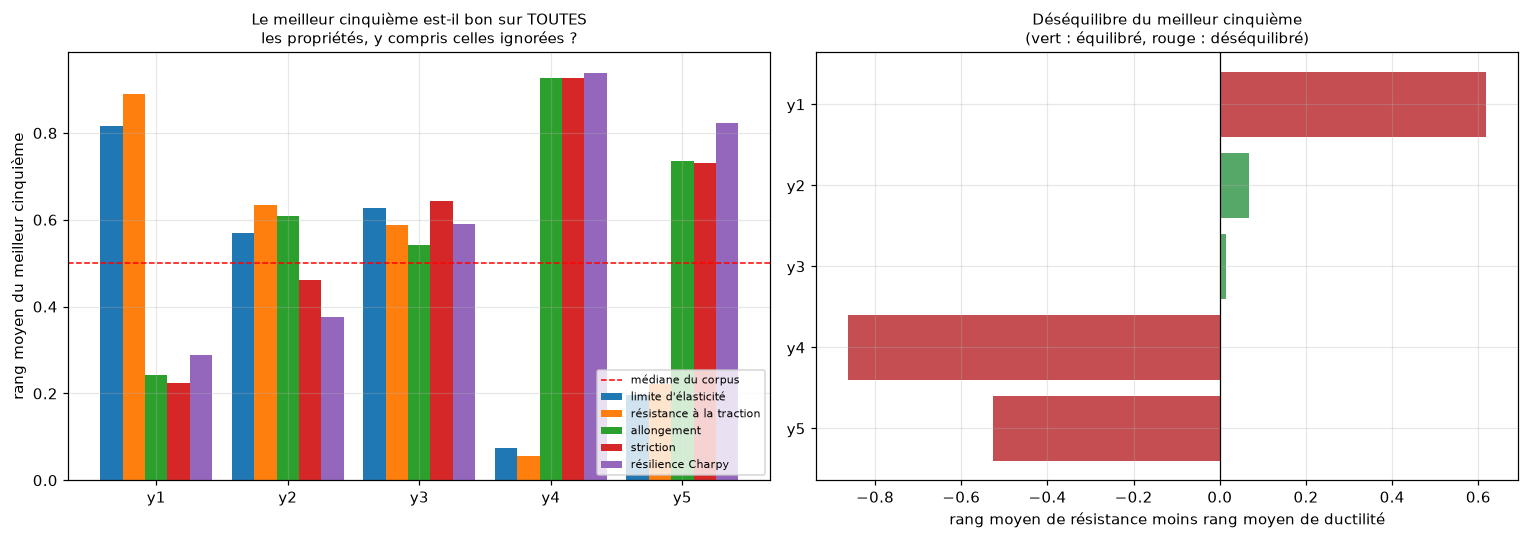

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))

positions = np.arange(len(coherence))
largeur = 0.17
for decalage, mesure in zip([-2, -1, 0, 1, 2], MESURES):
    axes[0].bar(positions + decalage * largeur,
                coherence[LIBELLES_MESURES[mesure]], largeur,
                label=LIBELLES_MESURES[mesure])
axes[0].axhline(0.5, color="red", linestyle="--", linewidth=1,
                label="médiane du corpus")
axes[0].set_xticks(positions, [n.split()[0] for n in coherence.index])
axes[0].set_ylabel("rang moyen du meilleur cinquième")
axes[0].set_title("Le meilleur cinquième est-il bon sur TOUTES\n"
                  "les propriétés, y compris celles ignorées ?", fontsize=10)
axes[0].legend(fontsize=7, loc="lower right")

couleurs = ["#55A868" if abs(d) < 0.15 else "#C44E52"
            for d in coherence["déséquilibre"]]
axes[1].barh(positions, coherence["déséquilibre"], color=couleurs)
axes[1].set_yticks(positions, [n.split()[0] for n in coherence.index])
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("rang moyen de résistance moins rang moyen de ductilité")
axes[1].set_title("Déséquilibre du meilleur cinquième\n"
                  "(vert : équilibré, rouge : déséquilibré)", fontsize=10)

figure.tight_layout()
figure.savefig(OUT / "coherence_physique.png", dpi=150)
plt.show()

### Le résultat qui tranche

**`y1`, la résistance seule, est disqualifiée.** Son meilleur cinquième est
excellent en résistance, ce qui est attendu, mais il se situe **sous la médiane
du corpus en allongement et en striction**. Son déséquilibre est de loin le plus
fort de toutes les candidates.

Autrement dit : un modèle entraîné sur `y1` recommanderait, avec une grande
confiance, les soudures les plus fragiles du corpus. C'est exactement le danger
annoncé en section 1.2, et il est ici mesuré.

**`y4`, la résilience brute, est disqualifiée pour la raison symétrique.** Son
meilleur cinquième est mauvais sur la résistance. Et `y5` améliore la situation
sans la régler : corriger la température rend les essais comparables mais ne
corrige pas le fait que la ténacité seule ignore la résistance.

**`y3` est la seule définition dont le meilleur cinquième est au-dessus de la
médiane sur les cinq propriétés**, y compris la résilience Charpy qu'elle
n'utilise pas. Son déséquilibre est le plus faible, proche de zéro.

**`y2`, notre premier choix, est correcte mais moins bonne.** Son meilleur
cinquième est bon sur trois propriétés et plus déséquilibré que celui de `y3`.
C'est logique : en ne gardant qu'une mesure par famille, elle utilise une
information plus pauvre et plus bruitée que `y3`, qui moyenne deux mesures par
famille.

### 4.4 La robustesse : la cible résiste-t-elle à un rééchantillonnage ?

Dernier critère sans modèle. Une définition dont le classement changerait
beaucoup si l'on retirait quelques soudures serait fragile, et nos conclusions
avec elle.

Nous tirons donc des échantillons bootstrap **au niveau des soudures**, et non
des lignes, recalculons la cible sur chaque tirage, et mesurons la stabilité de
son meilleur cinquième par l'indice de Jaccard, qui est la taille de
l'intersection divisée par celle de l'union.

In [9]:
generateur = np.random.default_rng(GRAINE)
soudures_dev = groupes[dev].unique()
N_TIRAGES = 30

lignes_robustesse = []
for nom in COMPOSITION_CIBLES:
    reference_top = meilleur_cinquieme(cibles.loc[dev, nom])
    jaccards = []
    for _ in range(N_TIRAGES):
        tirage = generateur.choice(soudures_dev, size=len(soudures_dev),
                                   replace=True)
        lignes_tirage = propre.index[groupes.isin(set(tirage)) & dev]
        if len(lignes_tirage) < 100:
            continue
        cible_tirage = construire_cible(nom, lignes_tirage)
        top_tirage = meilleur_cinquieme(cible_tirage.loc[dev])
        union = reference_top | top_tirage
        if union:
            jaccards.append(len(reference_top & top_tirage) / len(union))
    lignes_robustesse.append({
        "cible": LIBELLES[nom],
        "tirages": len(jaccards),
        "Jaccard moyen": np.mean(jaccards),
        "Jaccard minimum": np.min(jaccards),
    })

robustesse = pd.DataFrame(lignes_robustesse).set_index("cible")
robustesse.round(3)

Out[9]: 
                                        tirages  Jaccard moyen  Jaccard minimum
cible                                                                          
y1 résistance seule                          30          1.000            1.000
y2 résistance et allongement                 30          0.900            0.742
y3 quatre propriétés de traction             30          0.918            0.812
y4 résilience brute                          30          1.000            1.000
y5 résilience à température comparable       30          0.954            0.839


**Lecture, et ce critère demande de la prudence.**

**Les cibles fondées sur une seule propriété obtiennent un indice de 1 ou
presque, et c'est un artefact.** Une telle cible n'est que le classement de cette
propriété : retirer des soudures ne change pas l'ordre relatif de celles qui
restent, donc le meilleur cinquième est stable par construction. C'est le cas de
`y1` et `y4`, exactement à 1. C'est presque le cas de `y5`, dont seul le
découpage en bandes de température bouge d'un tirage à l'autre. **Leur stabilité
ne dit rien de leur qualité.**

**La comparaison informative est donc celle entre les deux scores de compromis**,
les seuls qui agrègent deux familles opposées et dont le classement peut
réellement se réorganiser. Entre eux, `y3` est plus stable que `y2`.

L'écart est faible et ne suffirait pas à trancher seul. Mais il va dans le même
sens que le critère de cohérence physique, et son explication est la même :
moyenner deux mesures par famille plutôt qu'une seule atténue le bruit propre à
chaque essai, donc le classement obtenu dépend moins de l'échantillon.

### 4.5 Synthèse des quatre critères

In [10]:
synthese = pd.DataFrame({
    "mesures combinées": couverture["mesures combinées"],
    "soudures couvertes": couverture["soudures"],
    "déséquilibre (valeur absolue)": coherence["déséquilibre"].abs(),
    "propriétés au-dessus de 0,5": coherence["propriétés au-dessus de 0,5"],
    "Jaccard moyen": robustesse["Jaccard moyen"],
})
display(synthese.round(3))

print("Rappel : le Jaccard des cibles à une seule mesure est un artefact.")
print("Le critère décisif est le nombre de propriétés au-dessus de la médiane.")

Rappel : le Jaccard des cibles à une seule mesure est un artefact.
Le critère décisif est le nombre de propriétés au-dessus de la médiane.


,mesures combinées,soudures couvertes,déséquilibre (valeur absolue),"propriétés au-dessus de 0,5",Jaccard moyen
cible,,,,,
y1 résistance seule,1,533,0.618,2,1.000
y2 résistance et allongement,2,480,0.068,3,0.900
y3 quatre propriétés de traction,4,469,0.015,5,0.918
y4 résilience brute,1,341,0.862,3,1.000
y5 résilience à température comparable,2,341,0.525,3,0.954


### 4.6 Le verdict, avant tout modèle

**Nous retenons `y3`**, la moyenne géométrique du rang moyen de résistance et du
rang moyen de ductilité, construite sur les quatre propriétés de traction.

Elle est la seule à satisfaire les quatre critères à la fois : elle couvre
presque autant de soudures que notre choix initial, son meilleur cinquième est
au-dessus de la médiane sur les cinq propriétés mesurées, elle est la plus stable
au rééchantillonnage, et son déséquilibre est le plus faible.

**Nous écartons `y1` et `y4`**, dont le meilleur cinquième est médiocre dans la
dimension qu'elles ignorent.

**Nous conservons `y5` comme problème séparé.** La ténacité est, selon les
auteurs du jeu de données eux-mêmes, la propriété la plus importante pour une
soudure. Elle mérite d'être prédite, mais sur son propre ensemble de soudures et
en étant corrigée de la température d'essai, et non fusionnée avec la traction.

Le notebook 4 traite la traction comme problème principal et mentionne la
ténacité comme extension.

## 5. La vérification par les modèles, et le piège évité

Nous entraînons maintenant des modèles. **Non pas pour choisir la cible, le choix
est fait, mais pour vérifier qu'il ne coûte rien en performance.**

Le protocole est celui de tout le projet : cinq plis par groupes, une forêt
aléatoire identique pour toutes les cibles, préparation et cible recalibrées
dans chaque pli. Seule la cible varie.

### Pourquoi on ne compare pas les erreurs directement

Nos cinq cibles vivent toutes entre 0 et 1, mais elles n'ont pas la même
**dispersion**. Une cible plus resserrée produit mécaniquement des erreurs plus
petites, indépendamment de la qualité du modèle.

Nous comparons donc le **gain par rapport à une référence** : pour chaque cible,
un prédicteur trivial annonce toujours la moyenne de l'apprentissage, sans
regarder les entrées. Le gain est la réduction d'erreur obtenue par le modèle
par rapport à lui. Cette grandeur est sans unité, donc comparable d'une cible à
l'autre.

```
gain  =  1  -  erreur du modèle  /  erreur de la référence
```

In [11]:
VARIABLES_ENTREE = nettoyage.COMPOSITION + nettoyage.PROCESS
CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
assert not set(VARIABLES_ENTREE) & set(MESURES)


def creer_preparation(X_apprentissage, seuil=0.25):
    """Préparation des entrées, détaillée dans le notebook 3."""
    taux = X_apprentissage.notna().mean()
    gardees = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in gardees if c not in CATEGORIES]
    categorielles = [c for c in gardees if c in CATEGORIES]
    return ColumnTransformer([
        ("nombres", SimpleImputer(strategy="median"), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


def evaluer_predictibilite(nom, n_plis=5):
    """Valide une forêt sur une cible, et la compare à une référence.

    La cible est recalibrée sur l'apprentissage de chaque pli : étant un rang,
    elle dépend des données, et la calibrer une fois pour toutes ferait fuir
    vers l'apprentissage une information issue de la validation.
    """
    index = propre.index[domaine(COMPOSITION_CIBLES[nom]) & dev]
    X = propre.loc[index, VARIABLES_ENTREE]
    g = groupes.loc[index]
    resultats = []

    for train, validation in GroupKFold(n_splits=n_plis).split(X, groups=g):
        ids_train, ids_val = index[train], index[validation]
        assert set(g.loc[ids_train]).isdisjoint(set(g.loc[ids_val]))

        y = construire_cible(nom, ids_train)
        poids_train = poids_par_soudure(g.loc[ids_train]).to_numpy()
        poids_val = poids_par_soudure(g.loc[ids_val]).to_numpy()
        preparation = creer_preparation(X.loc[ids_train])

        for etiquette, modele in [
                ("modèle", RandomForestRegressor(
                    n_estimators=300, max_features=0.25, random_state=GRAINE,
                    n_jobs=-1)),
                ("référence", DummyRegressor(strategy="mean"))]:
            pipeline = Pipeline([("preparation", creer_preparation(X.loc[ids_train])),
                                 ("modele", modele)])
            pipeline.fit(X.loc[ids_train], y.loc[ids_train],
                         modele__sample_weight=poids_train)
            prediction = pipeline.predict(X.loc[ids_val])
            resultats.append({
                "quoi": etiquette,
                "erreur": np.sqrt(mean_squared_error(
                    y.loc[ids_val], prediction, sample_weight=poids_val)),
                "R2": r2_score(y.loc[ids_val], prediction,
                               sample_weight=poids_val),
            })

    table = pd.DataFrame(resultats).groupby("quoi")[["erreur", "R2"]].mean()
    return {"lignes": len(index),
            "erreur du modèle": table.loc["modèle", "erreur"],
            "erreur de la référence": table.loc["référence", "erreur"],
            "R2": table.loc["modèle", "R2"],
            "gain": 1 - table.loc["modèle", "erreur"]
                    / table.loc["référence", "erreur"]}


predictibilite = pd.DataFrame(
    {LIBELLES[nom]: evaluer_predictibilite(nom)
     for nom in ["y1", "y2", "y3", "y5"]}).T
predictibilite.round(4)

Out[11]: 
                                        lignes  ...    gain
y1 résistance seule                      599.0  ...  0.5342
y2 résistance et allongement             539.0  ...  0.3058
y3 quatre propriétés de traction         527.0  ...  0.3519
y5 résilience à température comparable   684.0  ...  0.2583

[4 rows x 5 columns]


/Users/Marie/Documents/projet-soudures/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/Marie/Documents/projet-soudures/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/Marie/Documents/projet-soudures/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/Marie/Documents/projet-soudures/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transfo

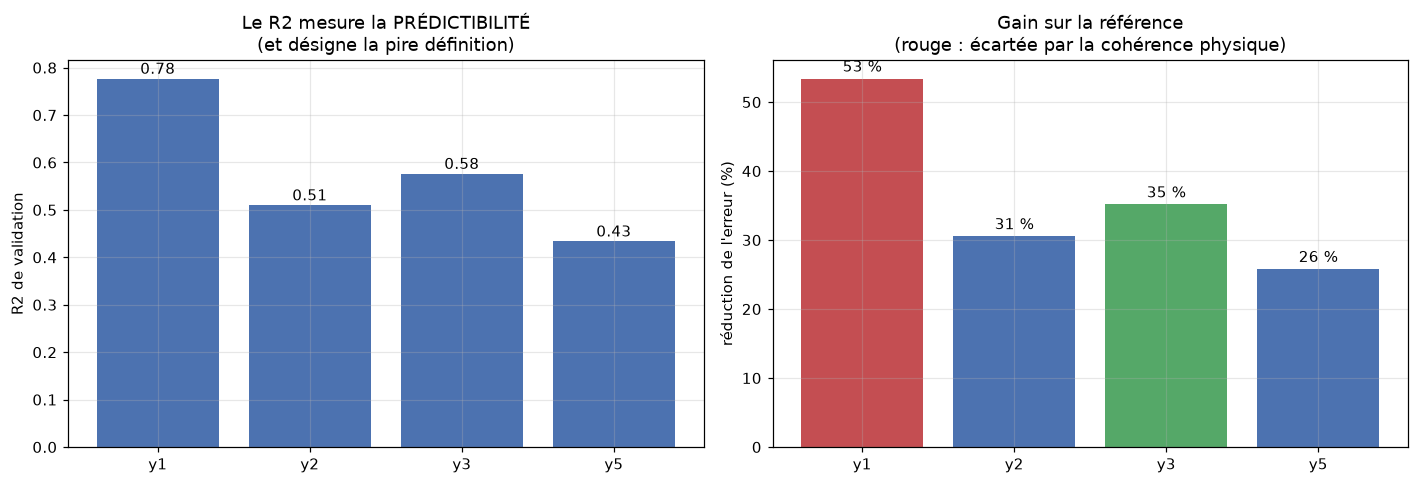

In [12]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
courts = [n.split()[0] for n in predictibilite.index]

axes[0].bar(courts, predictibilite["R2"], color="#4C72B0")
axes[0].set(ylabel="R2 de validation",
            title="Le R2 mesure la PRÉDICTIBILITÉ\n"
                  "(et désigne la pire définition)")
for position, valeur in enumerate(predictibilite["R2"]):
    axes[0].text(position, valeur + 0.01, f"{valeur:.2f}", ha="center")

couleurs = ["#C44E52" if c == "y1" else "#55A868" if c == "y3" else "#4C72B0"
            for c in courts]
axes[1].bar(courts, 100 * predictibilite["gain"], color=couleurs)
axes[1].set(ylabel="réduction de l'erreur (%)",
            title="Gain sur la référence\n"
                  "(rouge : écartée par la cohérence physique)")
for position, valeur in enumerate(100 * predictibilite["gain"]):
    axes[1].text(position, valeur + 1, f"{valeur:.0f} %", ha="center")

figure.tight_layout()
figure.savefig(OUT / "predictibilite.png", dpi=150)
plt.show()

### 5.1 Le piège, démontré

**`y1` est de loin la cible la mieux prédite.** Son R2 est le plus élevé du
projet, et son gain sur la référence dépasse largement celui des autres.

Or la section 4.3 a établi que son meilleur cinquième est constitué des soudures
les moins ductiles du corpus.

**Si nous avions choisi la cible sur la performance du modèle, nous aurions
retenu `y1`.** Nous aurions obtenu le meilleur R2 du projet, nous aurions pu le
présenter comme un succès, et nous aurions construit un outil recommandant des
soudures fragiles avec une grande confiance.

C'est la démonstration pratique de l'avertissement de la section 2. **La
prédictibilité et la pertinence sont deux propriétés indépendantes d'une cible**,
et seule la seconde justifie un choix.

### 5.2 Et la bonne nouvelle

**`y3` n'est pas plus difficile à prédire que `y2`.** Son R2 et son gain sont
tous deux supérieurs, ce qui lève la dernière objection possible au changement.

On pouvait craindre l'inverse : combiner quatre mesures agrège le bruit de quatre
essais. L'effet observé est le contraire, et il s'explique. Moyenner deux mesures
à l'intérieur d'une même famille, où elles sont fortement corrélées, **réduit**
le bruit propre à chaque essai au lieu de l'accumuler. Le signal physique en
ressort plus net.

**`y5` est la moins bien prédite**, pour deux raisons intrinsèques. La résilience
Charpy est une mesure très dispersée, car elle dépend de la microstructure à
l'endroit précis de l'entaille. Et le classement par bande de température retire
volontairement de la cible la variable qui explique le mieux la ténacité, à
savoir la température d'essai. Ce qui reste à prédire est donc plus difficile,
par construction. Cela ne la disqualifie pas, mais un modèle de ténacité devra
être présenté avec plus de réserve.

## 6. La limite de notre choix, mesurée

Il serait malhonnête de conclure sans mesurer la solidité de la construction
elle-même. `y3` repose sur trois conventions que rien n'impose :

1. à l'intérieur de chaque famille, les deux mesures sont **moyennées** ;
2. les deux familles sont combinées par **moyenne géométrique** ;
3. elles pèsent **autant** l'une que l'autre.

Nous faisons varier ces conventions et mesurons l'effet sur le classement.

In [13]:
def variantes_de_y3(lignes_calibration):
    """Construit y3 et des variantes qui ne diffèrent que par l'agrégation."""
    rangs = pd.DataFrame(index=propre.index)
    for mesure in RESISTANCE + DUCTILITE:
        reference = reference_rangs(propre.loc[lignes_calibration, mesure],
                                    groupes.loc[lignes_calibration])
        rangs[mesure] = appliquer_rangs(propre[mesure], reference)

    resistance = rangs[RESISTANCE].mean(axis=1)
    ductilite = rangs[DUCTILITE].mean(axis=1)
    masque = domaine(RESISTANCE + DUCTILITE)
    variantes = {
        "y3 de référence": np.sqrt(resistance * ductilite),
        "poids 25 % sur la résistance": resistance ** 0.25 * ductilite ** 0.75,
        "poids 75 % sur la résistance": resistance ** 0.75 * ductilite ** 0.25,
        "moyenne arithmétique": (resistance + ductilite) / 2,
        "minimum des deux familles": pd.concat([resistance, ductilite],
                                               axis=1).min(axis=1),
        "une seule mesure par famille": np.sqrt(rangs["UTS_MPa"]
                                                * rangs["Elongation_pct"]),
    }
    return {nom: valeur.where(masque) for nom, valeur in variantes.items()}


variantes = variantes_de_y3(lignes_dev)
reference_variante = variantes["y3 de référence"].loc[dev]
top_reference = meilleur_cinquieme(reference_variante)

lignes_sensibilite = []
for nom, valeur in variantes.items():
    serie = valeur.loc[dev]
    commun = reference_variante.notna() & serie.notna()
    top = meilleur_cinquieme(serie)
    lignes_sensibilite.append({
        "variante": nom,
        "corrélation de Spearman": spearmanr(reference_variante[commun],
                                             serie[commun]).statistic,
        "recouvrement du meilleur cinquième":
            len(top_reference & top) / len(top_reference),
    })
sensibilite = pd.DataFrame(lignes_sensibilite).set_index("variante")
sensibilite.round(3)

Out[13]: 
                              corrélation de Spearman  recouvrement du meilleur cinquième
variante                                                                                 
y3 de référence                                 1.000                               1.000
poids 25 % sur la résistance                    0.619                               0.547
poids 75 % sur la résistance                    0.782                               0.519
moyenne arithmétique                            0.817                               0.811
minimum des deux familles                       0.937                               0.736
une seule mesure par famille                    0.807                               0.585


### Ce que la sensibilité établit, et comment le présenter

**Le choix de l'opérateur a un effet modéré.** Remplacer la moyenne géométrique
par le minimum ou par une moyenne arithmétique conserve une large majorité du
meilleur cinquième. Ces variantes reclasseraient les soudures moyennes entre
elles mais recommanderaient en grande partie les mêmes bonnes soudures, ce qui
est l'usage qui nous intéresse.

**La pondération entre résistance et ductilité a un effet fort.** Donner trois
fois plus de poids à l'une qu'à l'autre ne conserve qu'environ la moitié du
meilleur cinquième. Selon la pondération, on recommanderait pour moitié des
soudures différentes.

**Cette sensibilité n'est pas un défaut de `y3`, et c'est important.** Nous
avions mené exactement la même étude sur notre première cible, dans le notebook
d'exploration 02, et obtenu des valeurs du même ordre. **C'est une propriété de
ce type de score de compromis, commune aux deux définitions**, et non un
inconvénient de la nouvelle.

**Trois arguments justifient néanmoins de conserver l'équilibre 50/50.**

Aucune information extérieure ne permettrait de faire autrement : privilégier la
résistance ou la ductilité supposerait de connaître l'usage final de la soudure,
que le jeu de données ne dit pas. En son absence, le traitement symétrique est le
seul neutre.

L'équilibre est précisément la propriété validée en section 4.3. Un `y3`
fortement déséquilibré perdrait sa cohérence sur les cinq propriétés et se
rapprocherait des candidates écartées.

Et c'est le choix déjà fait par notre première cible, donc le conserver maintient
la comparabilité entre les deux séries de résultats.

> **À retenir pour le rapport : la conclusion de ce notebook porte sur le
> périmètre des mesures retenues, pas sur la formule d'agrégation.** Ajouter la
> limite d'élasticité et la striction est argumenté par quatre critères
> indépendants. Le 50/50 et la moyenne géométrique sont une convention neutre, et
> doivent être présentés comme tels.

## 7. Une conséquence qui déplace la question

Un résultat obtenu plus tard dans le projet, en explorant la modélisation,
change la façon d'utiliser cette cible. Nous le mentionnons ici parce qu'il
concerne la définition de la qualité, et le notebook 4 le démontre.

**Deux soudures peuvent avoir le même score et des profils opposés.** Sur le
développement, parmi les soudures dont le score est très proche de 0,48, on
trouve une soudure à 663 mégapascals de limite d'élasticité et 22,5 %
d'allongement, et une autre à 435 mégapascals et 34 % d'allongement. Le score les
déclare équivalentes ; ce sont deux produits différents pour deux usages
différents.

C'est la conséquence inévitable d'un score agrégé : il indique le **niveau** du
compromis, pas la **position** sur ce compromis.

**La solution retenue, et c'est ce que fait le notebook 4 :** prédire les
**quatre propriétés séparément**, en unités physiques, puis recalculer le score à
partir des quatre prédictions. On obtient alors les deux lectures pour un seul
entraînement, et le score ne disparaît pas, il devient un indicateur de synthèse
calculé plutôt qu'une cible prédite directement.

Cette approche a de surcroît trois avantages mesurés dans le notebook 4 : elle
donne des valeurs directement lisibles par un métallurgiste, elle dispose de 7 à
20 % de lignes supplémentaires selon la propriété puisqu'elle n'exige plus les
quatre mesures simultanément, et elle prédit **mieux** le score agrégé que sa
prédiction directe.

In [14]:
# Illustration : deux soudures de score voisin et de profils opposés.
score_retenu = cibles.loc[dev, "y3"]
proches = score_retenu[(score_retenu > 0.47) & (score_retenu < 0.50)].index
extrait = propre.loc[proches, RESISTANCE + DUCTILITE].copy()
extrait["score y3"] = score_retenu[proches]
extrait["écart résistance moins ductilité"] = (
    rangs_proprietes.loc[proches, RESISTANCE].mean(axis=1)
    - rangs_proprietes.loc[proches, DUCTILITE].mean(axis=1))

print(f"{len(proches)} soudures ont un score entre 0,47 et 0,50, "
      "donc jugées équivalentes.\n")
display(pd.concat([
    extrait.nlargest(1, "écart résistance moins ductilité")
    .assign(profil="la plus résistante"),
    extrait.nsmallest(1, "écart résistance moins ductilité")
    .assign(profil="la plus ductile"),
])[["profil"] + RESISTANCE + DUCTILITE + ["score y3"]].round(2))

print("Étendue des propriétés à score quasi constant :")
display(extrait[RESISTANCE + DUCTILITE].agg(["min", "max"]).round(1))

36 soudures ont un score entre 0,47 et 0,50, donc jugées équivalentes.

Étendue des propriétés à score quasi constant :


,profil,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct,score y3
row_id,,,,,,
268,la plus résistante,738.0,789.0,20.0,67.0,0.47
456,la plus ductile,468.0,531.0,29.6,81.5,0.48


,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct
min,456.0,531.0,19.2,44.0
max,738.0,829.0,33.0,81.5


## 8. La cible retenue, exportée pour la suite

Nous produisons le fichier que les notebooks suivants consomment. Trois
précautions.

**Les rangs sont calibrés sur le développement seul**, puis appliqués à toutes
les lignes du domaine, y compris celles de test. L'ensemble de test reste donc
disponible pour l'évaluation finale, sans qu'aucune information n'ait fui de lui
vers la construction de la cible.

**Les quatre mesures brutes sont conservées dans le fichier**, et pas seulement
le score. C'est indispensable pour le notebook 4, qui prédit chaque propriété
séparément, et cela permet de recalculer la cible autrement si besoin.

**Des contrôles de validité physique sont appliqués**, dont celui sur le taux
d'écrouissage introduit au notebook 1.

In [15]:
BORNES_PHYSIQUES = {"YieldStrength_MPa": (0, 2000), "UTS_MPa": (0, 2500),
                    "Elongation_pct": (0, 100), "ReductionArea_pct": (0, 100)}
for mesure, (minimum, maximum) in BORNES_PHYSIQUES.items():
    valeurs = propre[mesure].dropna()
    assert ((valeurs > minimum) & (valeurs <= maximum)).all(), \
        f"{mesure} hors bornes physiques"
comparables = propre[["UTS_MPa", "YieldStrength_MPa"]].dropna()
assert (comparables["UTS_MPa"] >= comparables["YieldStrength_MPa"]).all(), \
    "résistance inférieure à la limite d'élasticité"
print("Contrôles de validité physique : tous passent.")

MESURES_Y3 = COMPOSITION_CIBLES["y3"]
cible_exportee = cibles["y3"].rename("score_qualite")
lignes_exportees = cible_exportee.dropna().index

export = pd.concat([
    groupes.loc[lignes_exportees].rename("groupe"),
    partition.loc[lignes_exportees],
    propre.loc[lignes_exportees, ["WeldID"]],
    propre.loc[lignes_exportees, MESURES_Y3],
    cible_exportee.loc[lignes_exportees],
    propre.loc[lignes_exportees, VARIABLES_ENTREE],
], axis=1)
export.to_csv(OUT / "dataset_qualite.csv", index_label="row_id")

assert export["score_qualite"].between(0, 1).all()
print(f"\ndataset_qualite.csv : {len(export)} lignes, "
      f"{groupes.loc[lignes_exportees].nunique()} soudures, "
      f"{export.shape[1]} colonnes.")
print(f"   développement : "
      f"{int((export['partition'] == 'developpement').sum())} lignes")
print(f"   test réservé  : "
      f"{int((export['partition'] == 'test').sum())} lignes")
display(export.head(3).iloc[:, :10])

Contrôles de validité physique : tous passent.

dataset_qualite.csv : 650 lignes, 469 soudures, 38 colonnes.
   développement : 527 lignes
   test réservé  : 123 lignes


,groupe,partition,WeldID,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct,score_qualite,C,Si
row_id,,,,,,,,,,
0,11,developpement,Evans-Ni/CMn-1990/1991-0Aaw,392.0,466.0,31.9,80.6,0.206283,0.037,0.30
2,11,developpement,Evans-Ni/CMn-1990/1991-0Aht,370.0,456.0,35.2,80.6,0.131327,0.037,0.30
3,14,developpement,Evans-Ni/CMn-1990/1991-0Baw,413.0,498.0,31.2,80.6,0.315494,0.037,0.31


In [16]:
# Manifeste : permet de reconstruire la cible à l'identique, et d'appliquer
# les rangs du développement au test lors de l'évaluation finale.
references_exportees = {}
for mesure in MESURES_Y3:
    grille, rangs_grille = reference_rangs(propre.loc[dev, mesure],
                                           groupes[dev])
    references_exportees[mesure] = {"valeurs": grille.tolist(),
                                    "rangs": rangs_grille.tolist()}

manifeste = {
    "graine": GRAINE,
    "cible": "score_qualite",
    "formule": ("racine(moyenne(rang_limite_elasticite, rang_resistance) * "
                "moyenne(rang_allongement, rang_striction))"),
    "mesures": MESURES_Y3,
    "ponderation_entre_familles": 0.5,
    "calibration": ("developpement seulement, mi-rang pondere, "
                    "poids total de un par soudure"),
    "lignes_developpement": export.index[
        export["partition"] == "developpement"].tolist(),
    "lignes_test": export.index[export["partition"] == "test"].tolist(),
    "references_de_rangs": references_exportees,
}
(OUT / "manifeste_cible.json").write_text(
    json.dumps(manifeste, ensure_ascii=False, indent=2), encoding="utf-8")

couverture.to_csv(OUT / "couverture.csv", index_label="cible")
accords.to_csv(OUT / "accords.csv", index_label="paire")
coherence.to_csv(OUT / "coherence_physique.csv", index_label="cible")
robustesse.to_csv(OUT / "robustesse.csv", index_label="cible")
synthese.to_csv(OUT / "synthese_criteres.csv", index_label="cible")
predictibilite.to_csv(OUT / "predictibilite.csv", index_label="cible")
sensibilite.to_csv(OUT / "sensibilite_agregation.csv", index_label="variante")

print("manifeste et résultats enregistrés.")
for chemin in sorted(OUT.iterdir()):
    print("   ", chemin.name)

manifeste et résultats enregistrés.
    accords.csv
    coherence_physique.csv
    coherence_physique.png
    couverture.csv
    dataset_qualite.csv
    manifeste_cible.json
    predictibilite.csv
    predictibilite.png
    robustesse.csv
    sensibilite_agregation.csv
    synthese_criteres.csv


## 9. Ce que ce notebook établit

### 9.1 La décision

**La qualité d'une soudure est définie comme la moyenne géométrique de son rang
moyen de résistance et de son rang moyen de ductilité**, calculée sur les quatre
propriétés de traction, avec des rangs pondérés de sorte que chaque soudure pèse
un.

Ce choix repose sur quatre critères qui ne font appel à aucun modèle : la
couverture, l'accord entre définitions, la cohérence physique du meilleur
cinquième, et la robustesse au rééchantillonnage. C'est la cohérence physique
qui tranche : **`y3` est la seule définition dont le meilleur cinquième est
au-dessus de la médiane du corpus sur les cinq propriétés mesurées**, y compris
celles qu'elle n'utilise pas.

### 9.2 Le résultat le plus important

**La cible la mieux prédite est la pire définition.** La résistance seule obtient
le meilleur R2 du projet, et son meilleur cinquième réunit les soudures les moins
ductiles du corpus. Un projet qui aurait choisi sa cible sur la performance
aurait livré un modèle excellent recommandant des soudures fragiles.

Ce résultat justifie à lui seul d'avoir mené cette comparaison, et il n'aurait
pas pu être obtenu par une comparaison de performances.

### 9.3 Ce que nous écartons, et pourquoi

La **résistance seule** et la **résilience brute** sont écartées parce que leur
meilleur cinquième est médiocre dans la dimension qu'elles ignorent.

La **fusion de la traction et de la résilience** est écartée parce que les deux
familles d'essais portent sur des soudures largement différentes, comme le
notebook 1 l'a établi.

La **résilience corrigée de la température** est conservée comme problème
séparé, sur son propre ensemble de soudures, car la littérature sur ce jeu de
données la juge essentielle.

### 9.4 Les limites

**La sensibilité à la pondération est réelle.** Déplacer le poids entre
résistance et ductilité ne conserve que la moitié du meilleur cinquième. Notre
première cible présentait la même sensibilité : c'est une propriété de ce type de
score, et l'équilibre 50/50 est le seul traitement neutre en l'absence
d'information sur l'usage final.

**Il n'existe aucune vérité de référence.** Le jeu de données ne contient pas de
variable de qualité, donc aucun de nos critères ne peut démontrer qu'une
définition est la bonne. Ils établissent seulement que certaines ont des
propriétés vérifiables que les autres n'ont pas. C'est un argument de cohérence,
pas une preuve. Si une norme imposait un allongement minimal absolu, elle
primerait sur tout ce notebook.

**Le score agrégé masque la position sur le compromis.** Le notebook 4 y répond
en prédisant les quatre propriétés séparément puis en recalculant le score.